In [3]:
import pandas as pd
import seaborn as s
import matplotlib.pyplot as p



In [2]:
import pandas as pd
x1=pd.read_csv("pesticides.csv")
x1

,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.00
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.00
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.00
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.00
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.00
...,...,...,...,...,...,...,...
4344,Pesticides Use,Zimbabwe,Use,Pesticides (total),2012,tonnes of active ingredients,3375.53
4345,Pesticides Use,Zimbabwe,Use,Pesticides (total),2013,tonnes of active ingredients,2550.07
4346,Pesticides Use,Zimbabwe,Use,Pesticides (total),2014,tonnes of active ingredients,2185.07
4347,Pesticides Use,Zimbabwe,Use,Pesticides (total),2015,tonnes of active ingredients,2185.07


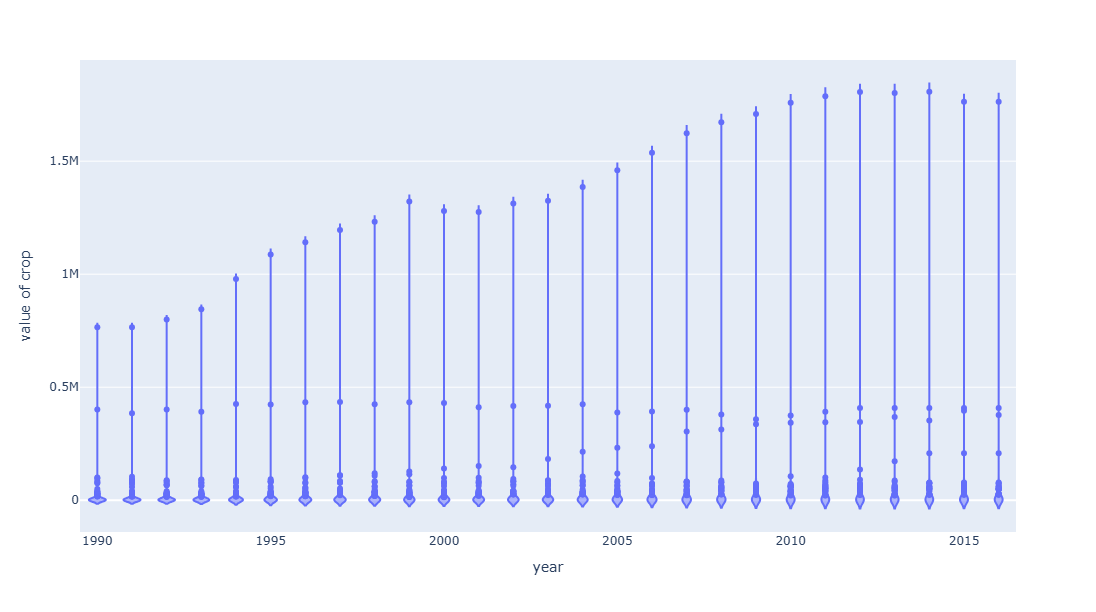

In [5]:
import plotly.express as px

fig=px.violin(x1,x='Year',y='Value')

fig.update_layout(xaxis_title='year',yaxis_title='value of crop',height=600,width=1200)

fig.show()




In [59]:
import plotly.express as px

x1['Value'] = pd.to_numeric(x1['Value'], errors='coerce')

region = x1.groupby('Area')['Value'].sum().reset_index()

fig = px.bar(region, x='Value', y='Area',
             orientation='h',
             color='Area',
             color_continuous_scale='Viridis',
             title='Total Pesticides Use by Country / Area')

fig.update_layout(
    xaxis_title='Total Pesticides Used (tonnes of active ingredients)',
    yaxis_title='Country / Area',
    height=900,
    width=1200,
    xaxis=dict(tickformat='d')  # scientific notation band
)

fig.show()

In [15]:

!pip install plotly



[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.9 MB 7.2 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.9 MB 5.3 MB/s eta 0:00:02
   --------------- ------------------------ 3.9/9.9 MB 6.7 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.9 MB 7.3 MB/s eta 0:00:01
   ------------------------------ --------- 7.6/9.9 MB 7.7 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.9 MB 7.9 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 7.8 MB/s  0:00:01

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   -------------------- ------------------- 1/2 [plotly]
   -------------------- ------------------- 1/2 [plotly]
   -------------------- ------------------- 1/2 [pl

In [10]:
import plotly.io as pio
pio.renderers.default = "notebook"

import plotly.express as px
fig = px.line(x1, x="Area", y="Value",
             title='Total Pesticides Use by Country / Area')
fig.show()

In [6]:
usa_x1 = x1[x1['Area'] == 'United States of America']
display(usa_x1)

,Domain,Area,Element,Item,Year,Unit,Value
4129,Pesticides Use,United States of America,Use,Pesticides (total),1990,tonnes of active ingredients,400975.93
4130,Pesticides Use,United States of America,Use,Pesticides (total),1991,tonnes of active ingredients,384646.39
4131,Pesticides Use,United States of America,Use,Pesticides (total),1992,tonnes of active ingredients,400975.90
4132,Pesticides Use,United States of America,Use,Pesticides (total),1993,tonnes of active ingredients,391903.86
4133,Pesticides Use,United States of America,Use,Pesticides (total),1994,tonnes of active ingredients,425922.68
4134,Pesticides Use,United States of America,Use,Pesticides (total),1995,tonnes of active ingredients,423201.53
4135,Pesticides Use,United States of America,Use,Pesticides (total),1996,tonnes of active ingredients,433180.36
4136,Pesticides Use,United States of America,Use,Pesticides (total),1997,tonnes of active ingredients,434540.76
4137,Pesticides Use,United States of America,Use,Pesticides (total),1998,tonnes of active ingredients,424562.11
4138,Pesticides Use,United States of America,Use,Pesticides (total),1999,tonnes of active ingredients,433633.96


In [62]:
import pandas as pd
y2=pd.read_csv("rainfall.csv")
y2

,area,Year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327
1,Afghanistan,1986,327
2,Afghanistan,1987,327
3,Afghanistan,1989,327
4,Afghanistan,1990,327
...,...,...,...
6722,Zimbabwe,2013,657
6723,Zimbabwe,2014,657
6724,Zimbabwe,2015,657
6725,Zimbabwe,2016,657


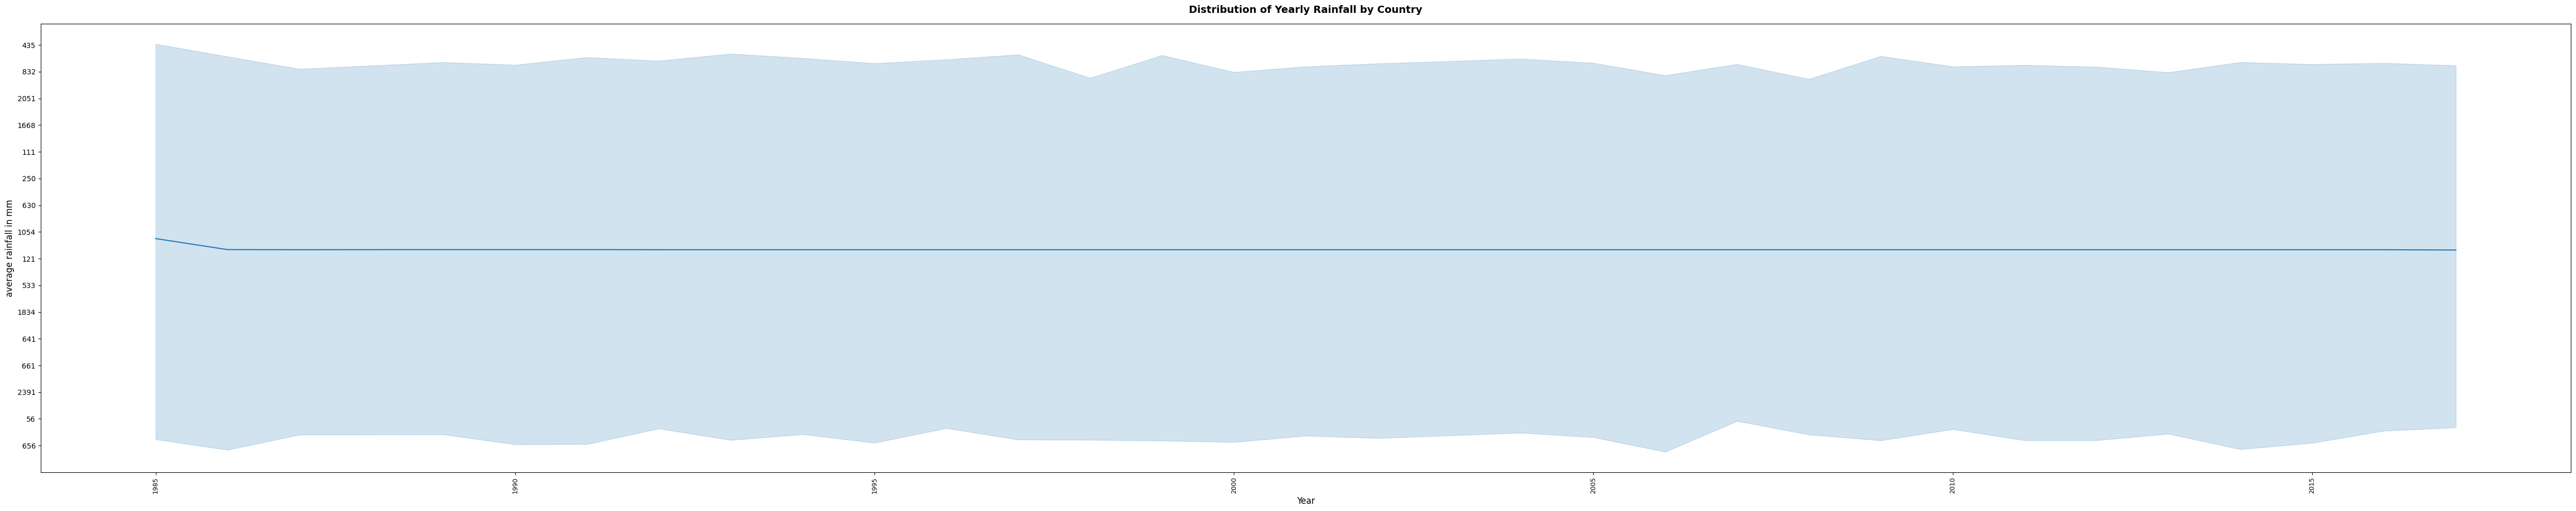

In [19]:
import matplotlib.pyplot as p
import seaborn as s


p.figure(figsize=(50,10))




s.lineplot(x='Year',y='average_rain_fall_mm_per_year', data=y2)


p.xticks(rotation=90,ha='center',fontsize=9)
p.title('Distribution of Yearly Rainfall by Country', fontsize=14, weight='bold', pad=15)
p.xlabel('Year', fontsize=12)
p.ylabel('average rainfall in mm', fontsize=12)

p.tight_layout()
p.show()

In [65]:
print(y2.columns.to_list())

[' area', 'Year', 'average_rain_fall_mm_per_year']


In [66]:
y2.columns.str.strip().str.lower()

Index(['area', 'year', 'average_rain_fall_mm_per_year'], dtype='object')

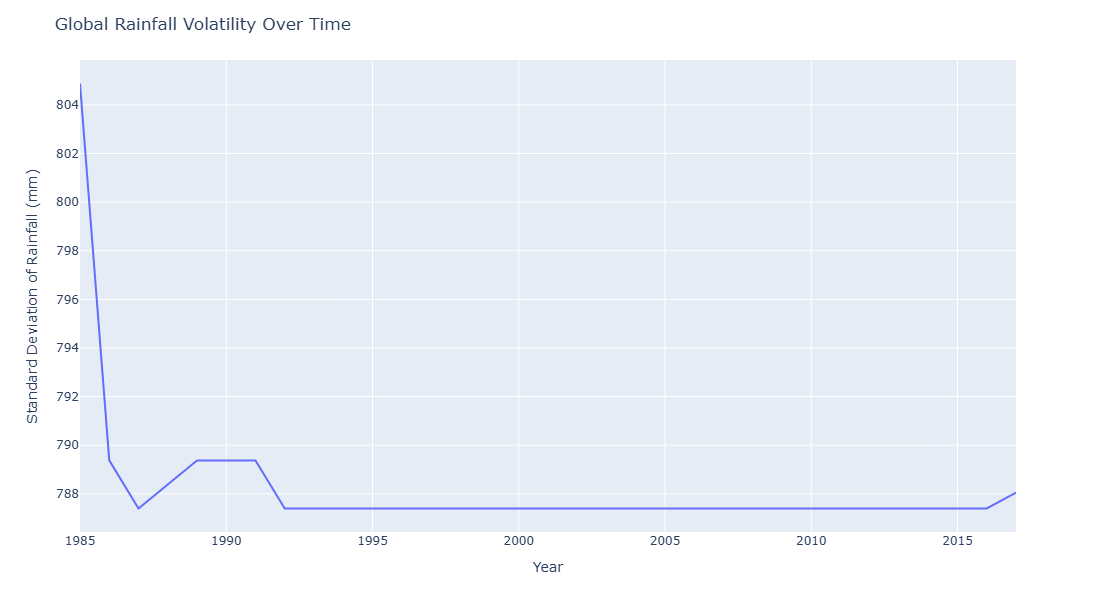

In [71]:

import plotly.express as pt


y2.columns = y2.columns.str.strip().str.lower()
y2['average_rain_fall_mm_per_year']=pd.to_numeric(y2['average_rain_fall_mm_per_year'],errors='coerce')



lu = y2.groupby('year')['average_rain_fall_mm_per_year'].std().reset_index()
lu = lu.dropna(subset=['average_rain_fall_mm_per_year'])

# 3. Plot the standard deviation line chart
fig = pt.line(lu, x='year', y='average_rain_fall_mm_per_year')

# 4. Add title and adjust layout bounds
fig.update_layout(
    xaxis_title='Year',
    yaxis_title='Standard Deviation of Rainfall (mm)',
    title='Global Rainfall Volatility Over Time',
    height=600,
    width=1300
)

fig.show()

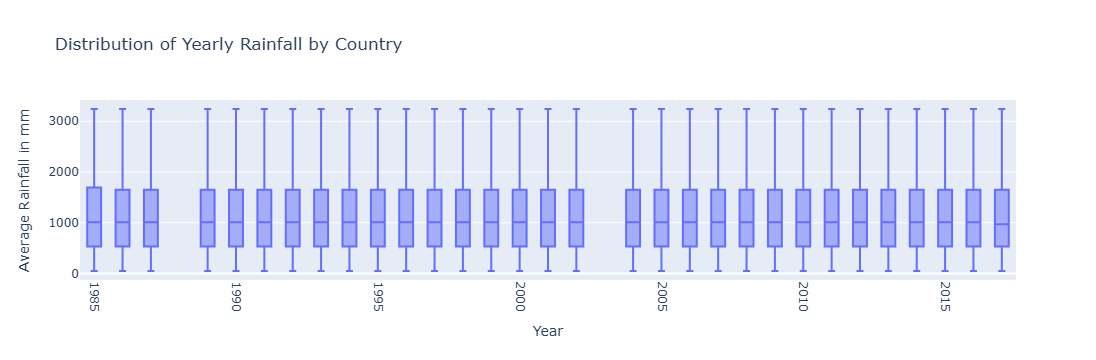

In [48]:
import plotly.express as px


y2.columns=y2.columns.str.strip().str.lower()


fig = px.box(y2, x='year', y='average_rain_fall_mm_per_year',
              title='Distribution of Yearly Rainfall by Country')

fig.update_layout(
    xaxis_title='Year',
    yaxis_title='Average Rainfall in mm',
    xaxis_tickangle=90
)

fig.show()

In [21]:
y2.head(20)

,area,year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327.0
1,Afghanistan,1986,327.0
2,Afghanistan,1987,327.0
3,Afghanistan,1989,327.0
4,Afghanistan,1990,327.0
5,Afghanistan,1991,327.0
6,Afghanistan,1992,327.0
7,Afghanistan,1993,327.0
8,Afghanistan,1994,327.0
9,Afghanistan,1995,327.0


In [25]:
y2.columns=y2.columns.str.strip()
print(y2.columns)

Index([nan, nan, nan], dtype='object')


In [5]:
import pandas as pd
y2=pd.read_csv('rainfall.csv')
y2

,area,Year,average_rain_fall_mm_per_year
0,Afghanistan,1985,327
1,Afghanistan,1986,327
2,Afghanistan,1987,327
3,Afghanistan,1989,327
4,Afghanistan,1990,327
...,...,...,...
6722,Zimbabwe,2013,657
6723,Zimbabwe,2014,657
6724,Zimbabwe,2015,657
6725,Zimbabwe,2016,657


In [27]:
y2.columns=y2.columns.str.strip()
print(y2.columns)

Index(['area', 'Year', 'average_rain_fall_mm_per_year'], dtype='object')


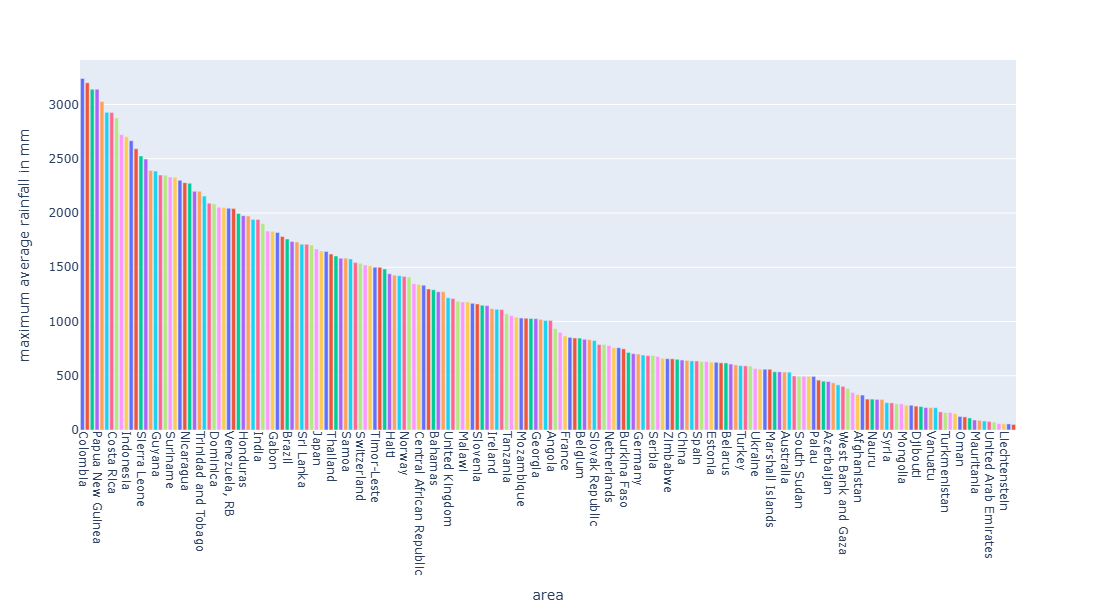

In [39]:

import pandas as pd
import plotly.express as pt


y2.columns=y2.columns.str.strip().str.lower()
y2['average_rain_fall_mm_per_year']=pd.to_numeric(y2['average_rain_fall_mm_per_year'],errors='coerce')

luv2=y2.groupby('area')['average_rain_fall_mm_per_year'].max().reset_index()
luv2 = luv2.sort_values('average_rain_fall_mm_per_year', ascending=False)
luv2 = luv2.dropna(subset=['average_rain_fall_mm_per_year'])


fig=pt.bar(luv2,x='area',y='average_rain_fall_mm_per_year',height=600,width=3500,color='area')




fig.update_layout(xaxis_title='area',yaxis_title='maximum average rainfall in mm',xaxis_tickangle=90,showlegend=False)

fig.show()

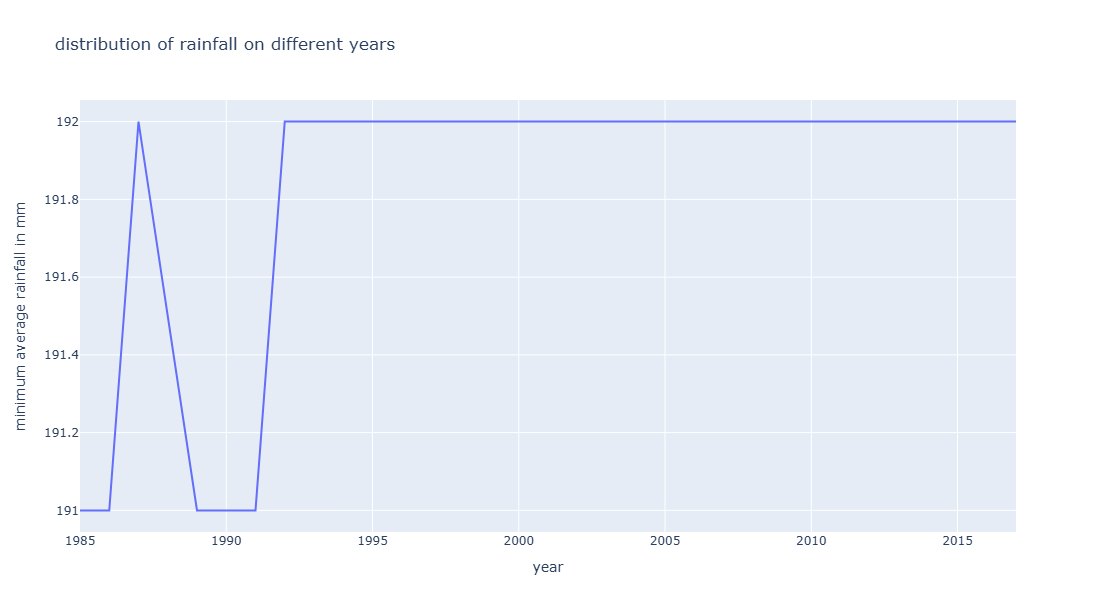

In [52]:
import pandas as pd
import plotly.express as pt

y2.columns=y2.columns.str.strip().str.lower()

y2['average_rain_fall_mm_per_year'] = pd.to_numeric(y2['average_rain_fall_mm_per_year'],errors='coerce')


luv2=y2.groupby('year')['average_rain_fall_mm_per_year'].count().reset_index()
luv2 = luv2.dropna(subset=['average_rain_fall_mm_per_year'])


fig=pt.line(luv2,x='year',y='average_rain_fall_mm_per_year',title='distribution of rainfall on different years',height=600,width=1300)
           
fig.update_layout(xaxis_title='year',yaxis_title='minimum average rainfall in mm')

fig.show()


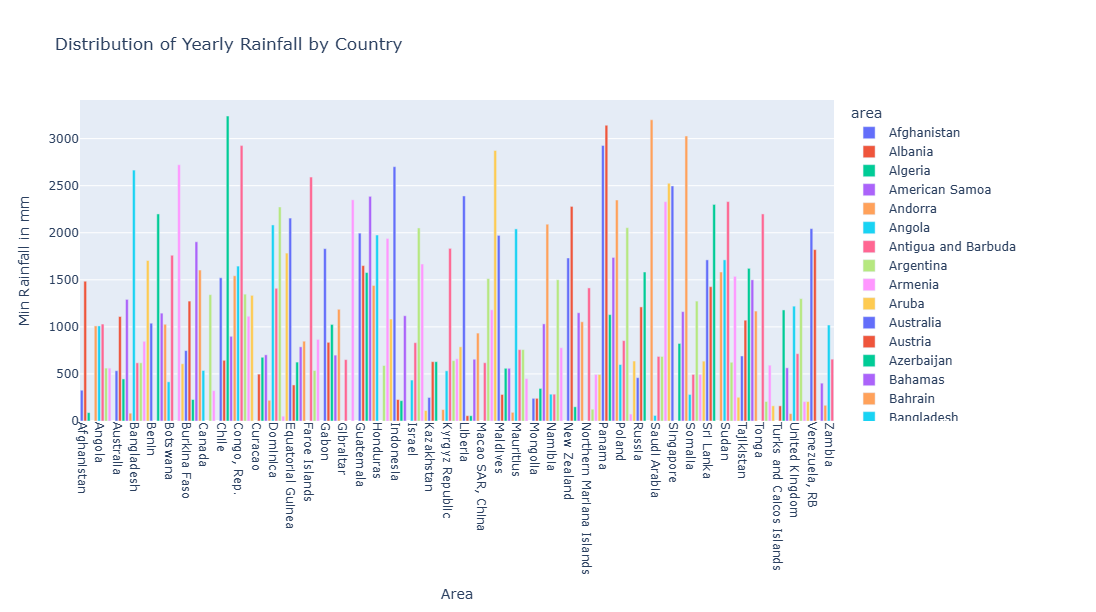

In [24]:
import plotly.express as px


y2['average_rain_fall_mm_per_year'] = pd.to_numeric(y2['average_rain_fall_mm_per_year'], errors='coerce')

luv2 = y2.groupby('area')['average_rain_fall_mm_per_year'].min().reset_index()

fig = px.bar(luv2, x='area', y='average_rain_fall_mm_per_year',
             title='Distribution of Yearly Rainfall by Country',color='area',width=2900)

fig.update_layout(
    xaxis_title='Area',
    yaxis_title='Min Rainfall in mm',
    xaxis_tickangle=90,
    height=600
)

fig.show()

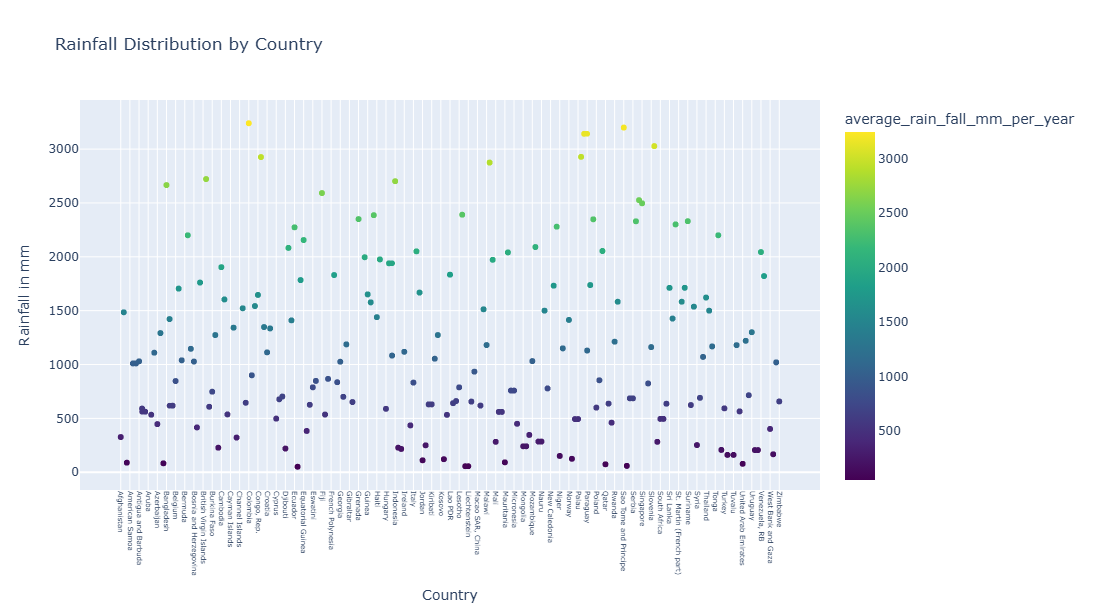

In [21]:
# Scatter plot — better dikhega is data ke liye
import plotly.express as px
fig = px.scatter(y2, x='area', y='average_rain_fall_mm_per_year',
                 color='average_rain_fall_mm_per_year',
                 color_continuous_scale='Viridis',
                 title='Rainfall Distribution by Country')

fig.update_layout(
    xaxis_title='Country',
    yaxis_title='Rainfall in mm',
    xaxis_tickangle=90,
    height=600,
    width=2100,
    xaxis_tickfont_size=7
)

fig.show()

In [23]:
import pandas as pd
x3=pd.read_csv("temp.csv")
x3


,year,country,avg_temp
0,1849,Côte D'Ivoire,25.58
1,1850,Côte D'Ivoire,25.52
2,1851,Côte D'Ivoire,25.67
3,1852,Côte D'Ivoire,NaN
4,1853,Côte D'Ivoire,NaN
...,...,...,...
71306,2009,Mexico,21.76
71307,2010,Mexico,20.90
71308,2011,Mexico,21.55
71309,2012,Mexico,21.52


In [47]:
import plotly.express as px

# Standardize column names
x3.columns = x3.columns.str.strip().str.lower()

# Calculate the mean temperature grouped by year
yearly_avg_temp = x3.groupby('year')['avg_temp'].mean().reset_index()

# Create the visualization using standard keyword arguments
fig = px.scatter(
    yearly_avg_temp, 
    x='year', 
    y='avg_temp', 
    title='Average Temperature vs Year'
)

# Apply corporate styling guidelines (clear labels, no cut-offs)
fig.update_layout(
    xaxis_title='Year',
    yaxis_title='Mean of Average Temperature (°C)',
    height=600,
    width=1600,
    margin=dict(l=100, r=50, b=100, t=100)
)

fig.show()

In [22]:
import plotly.express as px

# 1. Process your data exactly the same way
ok2 = x3.groupby('country')['avg_temp'].mean().reset_index()
ok2 = ok2.dropna(subset=['avg_temp'])
ok2=ok2.sort_values('avg_temp',ascending=False)



# 2. Create an interactive bar chart
fig = px.bar(
    ok2, 
    x='country', 
    y='avg_temp', 
    title='Average Temperature by Country'
)

# 3. Rotate the x-axis labels so they are readable
fig.update_layout(
    xaxis_tickangle=-60,
    xaxis_title="Country",
    yaxis_title="Avg Temp",
    margin=dict(b=100) ,# Adds padding at the bottom so long country names don't get cut of
    height=600,width=2000
)

# 4. Render the plot inside your notebook
fig.show()

In [34]:
import plotly.express as pt

fig=pt.violin(x3,x='country',y='avg_temp')

fig.update_layout(xaxis_title='country',yaxis_title='average temperature',width=3000,height=700)
fig.show()

In [1]:
# Install karo
!pip install ydata-profiling

# Use karo


  Using cached ydata_profiling-4.18.4-py2.py3-none-any.whl.metadata (23 kB)
  Using cached matplotlib-3.10.0-cp310-cp310-win_amd64.whl.metadata (11 kB)
  Using cached visions-0.8.1-py3-none-any.whl.metadata (11 kB)
  Using cached phik-0.12.5-cp310-cp310-win_amd64.whl.metadata (5.6 kB)
  Using cached statsmodels-0.14.6-cp310-cp310-win_amd64.whl.metadata (9.8 kB)
  Using cached ImageHash-4.3.2-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached wordcloud-1.9.6-cp310-cp310-win_amd64.whl.metadata (3.5 kB)
Using cached ydata_profiling-4.18.4-py2.py3-none-any.whl (400 kB)
Using cached ImageHash-4.3.2-py2.py3-none-any.whl (296 kB)
Using cached matplotlib-3.10.0-cp310-cp310-win_amd64.whl (8.0 MB)
Using cached phik-0.12.5-cp310-cp310-win_amd64.whl (674 kB)
Using cached statsmodels-0.14.6-cp310-cp310-win_amd64.whl (9.6 MB)
Using cached visions-0.8.1-py3-none-any.whl (105 kB)
Using cached wordcloud-1.9.6-cp310-cp310-win_amd64.whl (306 kB)

   ---------------------------------------- 0/7 [matplo

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\trilok\\AppData\\Local\\Programs\\Python\\Python310\\Lib\\site-packages\\matplotlib\\backends\\_backend_agg.cp310-win_amd64.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

y2.columns=y2.columns.str.strip()
print(y2.groupby('area')['Year'].nunique())


area
Afghanistan              31
Albania                  31
Algeria                  31
American Samoa           31
Andorra                  31
                         ..
Virgin Islands (U.S.)    31
West Bank and Gaza       31
Yemen                    31
Zambia                   31
Zimbabwe                 31
Name: Year, Length: 217, dtype: int64


In [30]:
import pandas as pd

x4=pd.read_csv('yield.csv')
x4

,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400
...,...,...,...,...,...,...,...,...,...,...,...,...
56712,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2012,2012,hg/ha,24420
56713,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2013,2013,hg/ha,22888
56714,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2014,2014,hg/ha,21357
56715,QC,Crops,181,Zimbabwe,5419,Yield,15,Wheat,2015,2015,hg/ha,19826


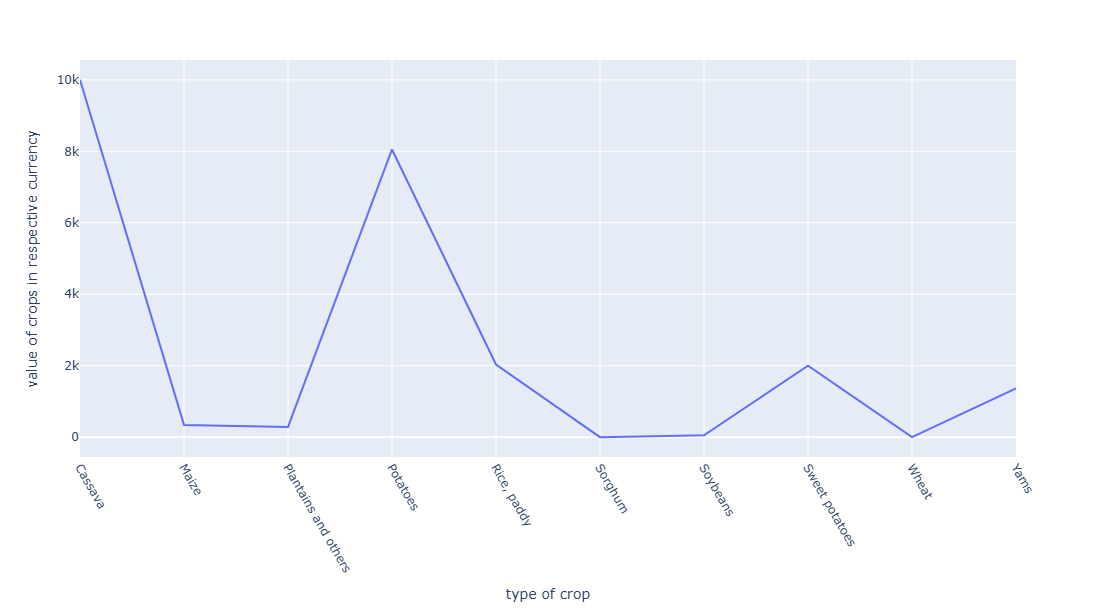

In [15]:
import plotly.express as pt

x4.columns=x4.columns.str.strip().str.lower()

luv4=x4.groupby('item')['value'].min().reset_index()


fig=pt.line(luv4,x='item',y='value',height=600,width=1200)

fig.update_layout(xaxis_title='type of crop',yaxis_title='value of crops in respective currency',xaxis_tickangle=60)

fig.show()

In [33]:
import plotly.express as pt

x4.columns=x4.columns.str.strip().str.lower()

luv4=x4.groupby(['area','item'])['value'].min().reset_index()


fig=pt.bar(luv4,x='area',y='value',color='item',height=600,width=5500)

fig.update_layout(xaxis_title='area',yaxis_title='value of crops in respective currency',xaxis_tickangle=90)

fig.show()